## Autocorrelation, AR, and MA Models

### Learning Goals
* Understand the structure of Autoregressive AR(1) and Moving Average MA(1) time-series processes.
* Simulate and visualize stationary time series and their autocorrelation functions (ACF).
* Analyze how persistence ($\phi$) affects temporal memory and shock decay.

---

### 1. Autoregressive and Moving Average Processes

An **Autoregressive process of order 1, AR(1)**, expresses the current value as a linear function of its immediate past plus a white-noise shock:
$$
y_t = c + \phi y_{t-1} + \epsilon_t
$$
If $|\phi| < 1$, the process is stationary, meaning shocks eventually die out and the series reverts to its long-run mean.

By contrast, a **Moving Average process, MA(1)**, models the current value as a linear combination of current and past white-noise shocks.

<>:17: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:17: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/tmp/ipykernel_3878/2894708815.py:17: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  axes[0].set_title(f"Simulated AR(1) Process ($\phi = {phi}$)")


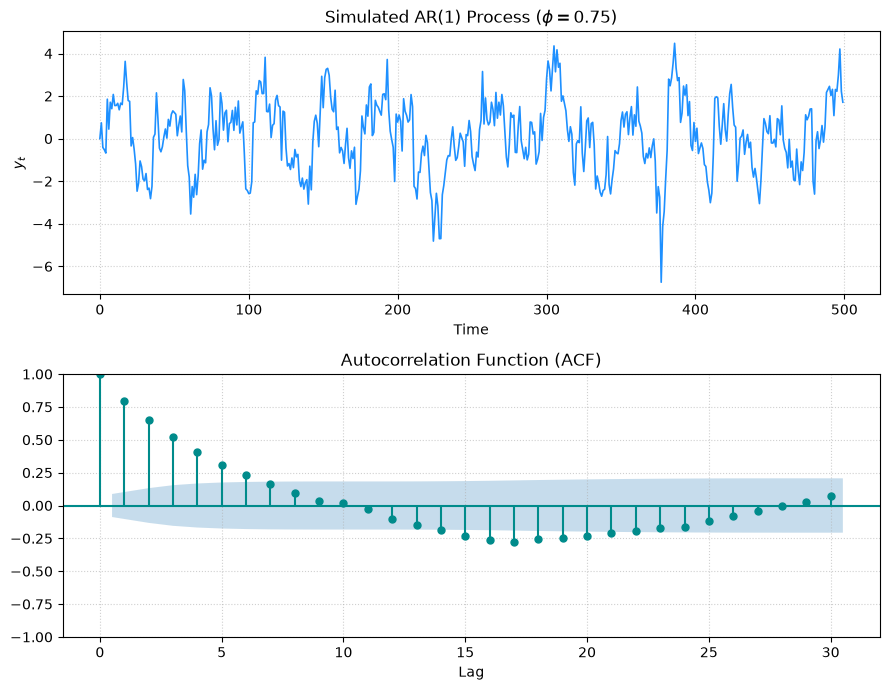

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

rng = np.random.default_rng(30)
n = 500
phi = 0.75
y = np.zeros(n)
errors = rng.normal(size=n)

for t in range(1, n):
    y[t] = phi * y[t-1] + errors[t]

fig, axes = plt.subplots(2, 1, figsize=(9, 7))

axes[0].plot(y, color='dodgerblue', linewidth=1.2)
axes[0].set_title(f"Simulated AR(1) Process ($\phi = {phi}$)")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("$y_t$")
axes[0].grid(linestyle=':', alpha=0.6)

# Plot Autocorrelation Function (ACF)
plot_acf(y, lags=30, ax=axes[1], color='darkcyan', vlines_kwargs={'colors': 'darkcyan'})
axes[1].set_title("Autocorrelation Function (ACF)")
axes[1].set_xlabel("Lag")
axes[1].grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---

### Exercises

Try each problem before running the verification code below:

1. Simulate an AR(1) process with a low persistence parameter ($\phi = 0.2$) and observe the trajectory.
2. Compare it with a highly persistent series ($\phi = 0.95$). How does the ACF differ?
3. What does autocorrelation tell you about temporal dependence? What does it *not* prove?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1 & 2 Simulation Check
n_sim = 300
eps = rng.normal(size=n_sim)
y_low = np.zeros(n_sim)
y_high = np.zeros(n_sim)

for t in range(1, n_sim):
    y_low[t] = 0.2 * y_low[t-1] + eps[t]
    y_high[t] = 0.95 * y_high[t-1] + eps[t]

print(f"\n1 & 2. AR(1) Persistence Comparison:")
print(f"   - Low Persistence (phi = 0.2): Rapid mean reversion, short memory (ACF drops quickly).")
print(f"   - High Persistence (phi = 0.95): Slow mean reversion, long memory (ACF decays very gradually).")

print("\n3. What Autocorrelation Tells Us:")
print(f"   - Autocorrelation confirms that past values contain predictive linear information about")
print(f"     future values, but it does not prove a direct causal mechanism (e.g., common trends or cycles).")

=== Exercise Solutions & Checks ===

1 & 2. AR(1) Persistence Comparison:
   - Low Persistence (phi = 0.2): Rapid mean reversion, short memory (ACF drops quickly).
   - High Persistence (phi = 0.95): Slow mean reversion, long memory (ACF decays very gradually).

3. What Autocorrelation Tells Us:
   - Autocorrelation confirms that past values contain predictive linear information about
     future values, but it does not prove a direct causal mechanism (e.g., common trends or cycles).
